# Solutions

In [1]:
import hashlib

import matplotlib.pyplot as plt
import numpy as np

# The photos are stored in the course repository
BASE = "https://raw.githubusercontent.com/daniprec/Python-Course/main/data/ghost_photos"


def show(image):
    """Display an image: a 2D array (grayscale, 0 = black, 1 = white) or a 3D array (colour)."""
    if image.ndim == 2:
        plt.imshow(image, cmap="gray", vmin=0, vmax=1)
    else:
        plt.imshow(np.clip(image, 0, 1))
    plt.axis("off")
    plt.show()


_KEYS = {
    1: "acba8dd74b724348",
    2: "f5ca38f748a1d6ea",
    3: "9ae2bdd7beedc2e7",
    4: "d4735e3a265e16ee",
    5: "72440a20f54075ac",
    "case": "a81745a221f746f4",
}


def check(photo, key):
    """Check the key of a photo (1 to 5) or of the case ("case")."""
    digest = hashlib.sha256(str(key).strip().upper().encode()).hexdigest()[:16]
    if digest != _KEYS[photo]:
        print(f"Wrong key for photo {photo}. Keep investigating...")
    elif photo == "case":
        print("Correct case number! The ghost hunt is solved.")
    else:
        print(f"Correct key! Photo {photo} is recovered.")

## Photo 1: The Shattered Photo

(300, 300)


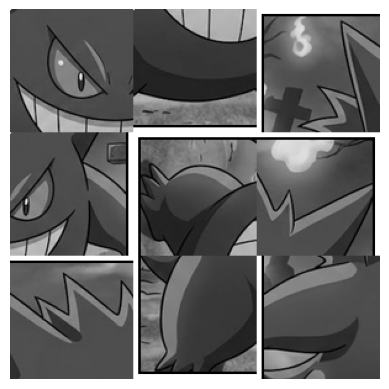

In [2]:
shattered = np.loadtxt(f"{BASE}/photo_1/shattered.txt")
print(shattered.shape)
show(shattered)

Cut it into three rows of fragments (`np.vsplit()`), then each row into three fragments (`np.hsplit()`). The list `fragments` keeps the order A, B, ..., I:

In [3]:
letters = "ABCDEFGHI"
fragments = []

for row in np.vsplit(shattered, 3):
    for fragment in np.hsplit(row, 3):
        fragments.append(fragment)

numbers = np.array([fragment[0, 0] for fragment in fragments])
print(numbers)

[5. 8. 1. 6. 9. 3. 2. 7. 4.]


`np.argsort()` gives the places that sort the fragment numbers. The key is the letters in that order.

CGFIADHBE
Correct key! Photo 1 is recovered.


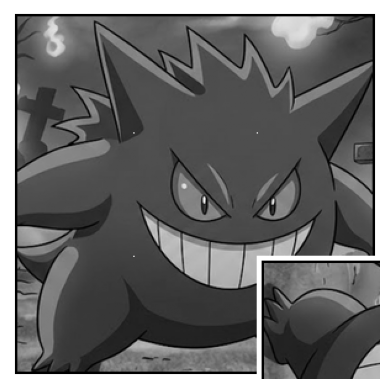

In [4]:
order = np.argsort(numbers)
key = "".join(letters[i] for i in order)
print(key)
check(1, key)

sorted_fragments = [fragments[i] for i in order]
photo_1 = np.vstack(
    [np.hstack(sorted_fragments[r * 3 : (r + 1) * 3]) for r in range(3)]
)
show(photo_1)

**The secret twist (not on the students' page).** The bottom-right fragment is wrong: its white frame is on the top and on the left. The camera mirrored it along the **anti-diagonal** (from bottom-left to top-right). `.T` mirrors along the main diagonal, so we flip the fragment upside down and left to right first. Any combination that works is fine, for instance `np.rot90(fragment, 2).T`.

The key does not notice the twist, but the case number does: the digit region cuts through this fragment.

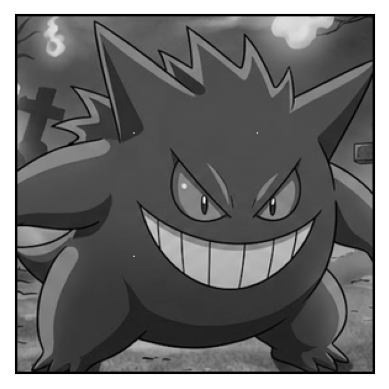

In [5]:
sorted_fragments[8] = sorted_fragments[8][::-1, ::-1].T
photo_1 = np.vstack(
    [np.hstack(sorted_fragments[r * 3 : (r + 1) * 3]) for r in range(3)]
)
show(photo_1)

The white dots in the corners of the fragments are the fragment numbers: values above 1 are shown as white.

## Photo 2: The Frozen Photo

In [6]:
frozen = np.loadtxt(f"{BASE}/photo_2/frozen.txt")
print(frozen.shape)

(90000,)


90,000 values: `reshape()` gives the photo back its $300 \times 300$ shape. It is so faint that it looks plain gray:

0.31 0.36


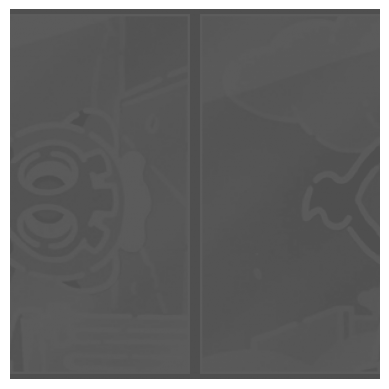

In [7]:
stored = frozen.reshape(300, 300)
print(stored.min(), stored.max())
show(stored)

Swap the two halves:

In [8]:
left, right = np.hsplit(stored, 2)
stored = np.hstack((right, left))

Stretch the values back to $[0, 1]$:

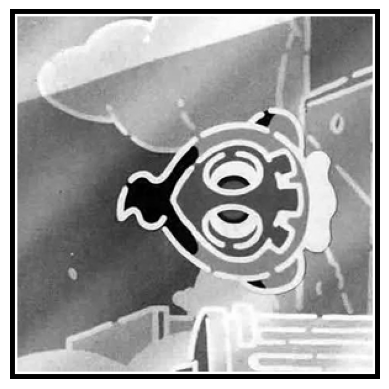

In [9]:
stretched = (stored - stored.min()) / (stored.max() - stored.min())
show(stretched)

A negative, mirrored along the diagonal. Undo both:

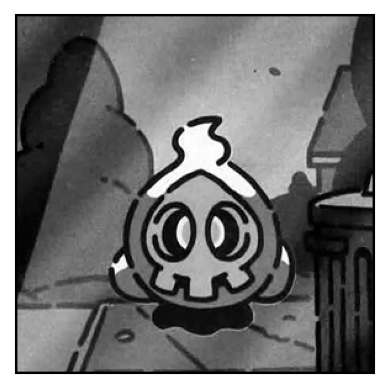

20
Correct key! Photo 2 is recovered.


In [10]:
photo_2 = (1 - stretched).T
show(photo_2)

key = round(1 / (stored.max() - stored.min()))
print(key)
check(2, key)

## Photo 3: The Banded Photo

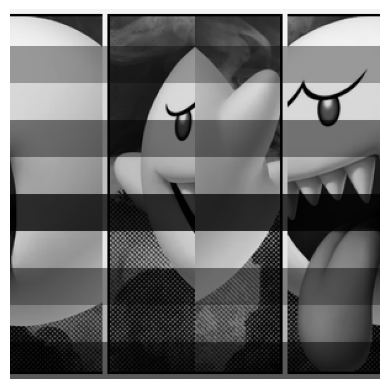

In [11]:
banded = np.loadtxt(f"{BASE}/photo_3/banded.csv", delimiter=";")

show(banded)

0 (300, 75)


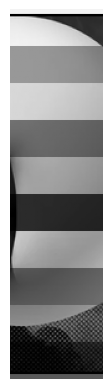

1 (300, 75)


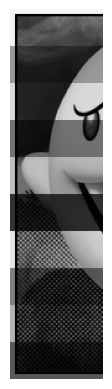

2 (300, 75)


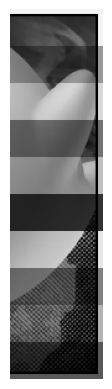

3 (300, 75)


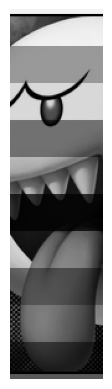

In [12]:
strips = np.hsplit(banded, 4)

for k, strip in enumerate(strips):
    print(k, strip.shape)
    show(strip)

Strip 1 has the black line on its left edge, and strip 2 on its right edge. Two orders are left for strips 0 and 3:

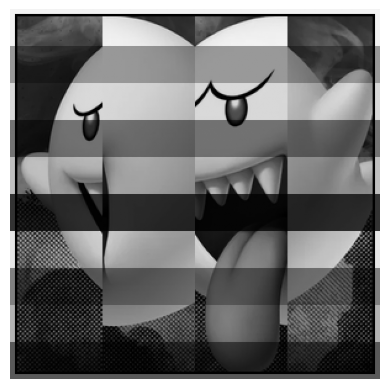

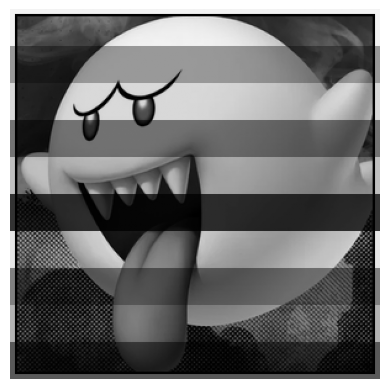

In [13]:
show(np.hstack((strips[1], strips[0], strips[3], strips[2])))
show(np.hstack((strips[1], strips[3], strips[0], strips[2])))

The second one is the right order:

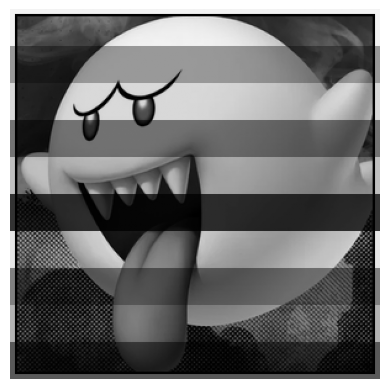

In [14]:
stored = np.hstack((strips[1], strips[3], strips[0], strips[2]))
show(stored)

The first column of the original photo is the white frame (all `1`), so the first column of `stored` is the gain of each row:

In [15]:
gain = stored[:, 0]
print(gain.shape)
print(gain[:40])

(300,)
[0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95
 0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95
 0.95 0.95 0.6  0.6  0.6  0.6  0.6  0.6  0.6  0.6  0.6  0.6 ]


`gain` has shape `(300,)`, so broadcasting treats it as a **row** and divides the columns. We need a column, `(300, 1)`, to divide the rows:

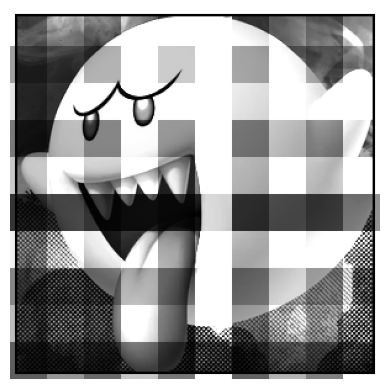

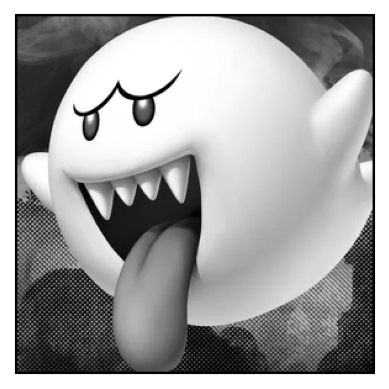

150
Correct key! Photo 3 is recovered.


In [16]:
show(stored / gain)  # wrong: divides each column

photo_3 = stored / gain.reshape(-1, 1)  # right: divides each row
show(photo_3)

key = np.argmin(gain)
print(key)
check(3, key)

The bands are also visible in the mean of each row (`axis=1`):

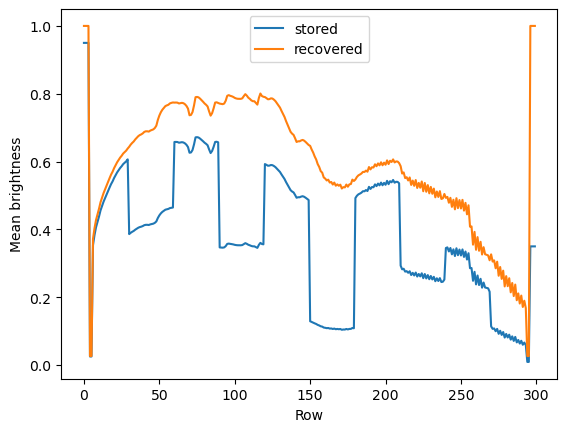

In [17]:
plt.plot(np.mean(stored, axis=1), label="stored")
plt.plot(np.mean(photo_3, axis=1), label="recovered")
plt.xlabel("Row")
plt.ylabel("Mean brightness")
plt.legend()
plt.show()

## Photo 4: The Cursed Lens

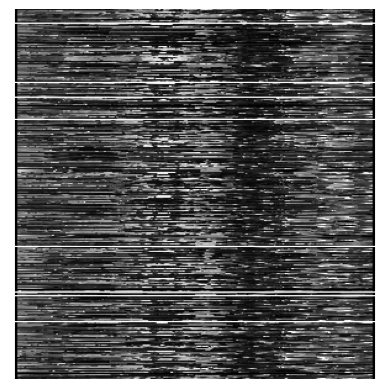

In [18]:
cursed = np.loadtxt(f"{BASE}/photo_4/cursed.csv", delimiter=",")
show(cursed)

[4. 1. 5. 3. 2.]


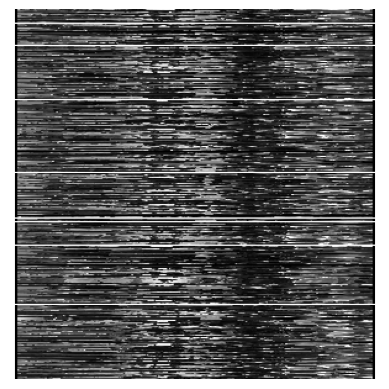

In [19]:
cursed = np.loadtxt(f"{BASE}/photo_4/cursed.csv", delimiter=",")
strips = np.vsplit(cursed, 5)

numbers = np.array([strip[0, 0] for strip in strips])
print(numbers)

order = np.argsort(numbers)
stored = np.vstack([strips[i] for i in order])
show(stored)

Now, the lenses:

In [20]:
lenses = {}

for k in range(1, 4):
    L = np.loadtxt(f"{BASE}/photo_4/lens_{k}.csv", delimiter=",")
    lenses[k] = L
    print(f"lens_{k}: shape {L.shape}, determinant {np.linalg.det(L):.1f}")

lens_1: shape (300, 300), determinant 0.0
lens_2: shape (300, 300), determinant -1.0
lens_3: shape (300, 300), determinant 0.0


Lenses 1 and 3 have determinant 0: they have no inverse.

In [21]:
np.linalg.inv(lenses[1])

LinAlgError: Singular matrix

In [ ]:
key = 2
check(4, key)

L = lenses[key]
photo_4 = np.linalg.inv(L) @ stored
show(photo_4)

`L` only moves rows around, so its inverse is its transpose. The strip numbers end up in the first column, inside the white frame:

In [ ]:
print(np.allclose(np.linalg.inv(L), L.T))
print(np.allclose(L.T @ stored, photo_4))

## Photo 5: The Colour Photo

In [ ]:
colour = np.loadtxt(f"{BASE}/photo_5/colour.txt")
show(colour)

In [ ]:
colour = np.loadtxt(f"{BASE}/photo_5/colour.txt")
print(colour.shape)

images = {}
for k, image in enumerate(np.hsplit(colour, 4), start=1):
    images[k] = image
    print(k, image.shape)
    show(image)

Image 1 is static: the decoy. Stack the other three in any order and rebuild the photo, exactly as in photo 1: `vsplit()` and `hsplit()` cut rows and columns, and each fragment keeps its three channels.

In [ ]:
def rebuild(stacked):
    fragments = []
    for row in np.vsplit(stacked, 3):
        for fragment in np.hsplit(row, 3):
            fragments.append(fragment)
    order = np.argsort([fragment[0, 0, 0] for fragment in fragments])
    fragments = [fragments[i] for i in order]
    return np.vstack([np.hstack(fragments[r * 3 : (r + 1) * 3]) for r in range(3)])


attempt = np.sqrt(rebuild(np.stack((images[3], images[4], images[2]), axis=2)))
print(attempt.shape)
show(attempt)

Blue flames? A will-o'-the-wisp, not our ghost: wrong order. With three channels there are only $3 \times 2 \times 1 = 6$ possible orders, so we can try them all:

In [ ]:
orders = [(2, 3, 4), (2, 4, 3), (3, 2, 4), (3, 4, 2), (4, 2, 3), (4, 3, 2)]

for red, green, blue in orders:
    print("red:", red, "green:", green, "blue:", blue)
    show(np.sqrt(rebuild(np.stack((images[red], images[green], images[blue]), axis=2))))

Only one order shows orange flames, as the camera log said:

In [ ]:
photo_5 = np.sqrt(rebuild(np.stack((images[2], images[4], images[3]), axis=2)))
show(photo_5)
check(5, "243")

## The Case Number

The digit of each photo is the second decimal of the mean of `photo[150:, 150:250]`. For the colour photo, only the red channel (index 0 of the last axis).

In [ ]:
regions = [
    photo_1[150:, 150:250],
    photo_2[150:, 150:250],
    photo_3[150:, 150:250],
    photo_4[150:, 150:250],
    photo_5[150:, 150:250, 0],
]

case = ""
for region in regions:
    mean = np.mean(region)
    digit = int(mean * 100) % 10
    print(f"mean {mean:.4f} -> digit {digit}")
    case = case + str(digit)

print(case)
check("case", case)

A half-fixed photo gives a different digit. For instance, photo 2 without the transpose:

In [ ]:
print(int(np.mean((1 - stretched)[150:, 150:250]) * 100) % 10)

## Save the Evidence

In [ ]:
np.save("photo_1.npy", photo_1)
np.savetxt("photo_1.txt", photo_1, fmt="%.4f")
np.save("photo_5.npy", photo_5)

print(np.allclose(np.load("photo_1.npy"), photo_1))
print(np.allclose(np.loadtxt("photo_1.txt"), photo_1))
print(np.load("photo_5.npy").shape)  # .npy keeps the 3D shape

`np.savetxt()` only accepts 1D and 2D arrays, so it fails with the colour photo:

In [ ]:
np.savetxt("photo_5.txt", photo_5)

---

## Summary and Reflection

- `np.loadtxt()` loads text files, even straight from a URL; `delimiter` sets the separator of CSV files.
- `np.load()` loads `.npy` files from your computer.
- `np.save()` keeps an array exactly, with its shape and data type; `np.savetxt()` writes readable text, but only for 1D and 2D arrays.
- `np.concatenate()`, `np.hstack()`, and `np.vstack()` join arrays along an existing axis; `np.stack()` creates a new one. `np.split()`, `np.hsplit()`, and `np.vsplit()` undo the joining.
- Array arithmetic, broadcasting, aggregations, and matrix operations can undo many transformations, as long as we know what happened.

Which photo was the hardest to recover, and why? For each photo, how did you know that your result was correct?